# Algebra lineal con **SciPy**

Referencias:

* https://docs.scipy.org/doc/scipy/reference/linalg.html
* https://www.datacamp.com/cheat-sheet/scipy-cheat-sheet-linear-algebra-in-python

## **Ejercicio 1)** Importando librerías

Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

In [5]:
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

## **Ejercicio 2)** Inversa de una matriz

Referencias:

* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.inv.html#scipy.linalg.inv

**1)** Use `linalg.inv()` para calcular la inversa $A^{-1}$ de la matriz

\begin{equation}
A = \bigg(
\begin{array}{cc}
1 & 2 \\
3 & 4
\end{array}
\bigg)
\end{equation}

**2)** Use `np.dot()` para chequear que $A^{-1}A \approx \mathbb{I}$, donde $\mathbb{I}$ es la matriz identidad.

**3)** Chequee que $AA^{-1} \approx \mathbb{I}$.

In [9]:
# 2.1)

a = np.array([[1, 2], [3, 4]])
aInv = np.linalg.inv(a)

print(f"mayMul --> {np.matmul(a, aInv)}")
print(f"dot --> {np.dot(a, aInv)}")

print(f"matMul.2 --> {a @ aInv}")


mayMul --> [[1.0000000e+00 0.0000000e+00]
 [8.8817842e-16 1.0000000e+00]]
dot --> [[1.0000000e+00 0.0000000e+00]
 [8.8817842e-16 1.0000000e+00]]
matMul.2 --> [[1.0000000e+00 0.0000000e+00]
 [8.8817842e-16 1.0000000e+00]]


## **Ejercicio 3)** Sistema de ecuaciones lineales

Referencias:

* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve.html#scipy.linalg.solve

**1)** Use `linalg.solve()` para resolver el sistema $Ax=b$ donde, $x$ es la incógnita,

\begin{equation}
A = \left(
\begin{array}{cc}
3 & 2 & 0 \\
1 & -1 & 0 \\
0 & 5 & 1
\end{array}
\right)
\end{equation}

y

\begin{equation}
b = \left(
\begin{array}{cc}
2 \\
4 \\
1
\end{array}
\right)
\end{equation}

**2)** Chequee que $Ax=b$.

In [12]:
# 3.1)
a = np.array([[3, 2, 0], [1, -1, 0], [0, 5, 1]])
b = np.array([2, 4, 1])

x = linalg.solve(a, b)

print(f"a @ x --> {a @ x}")

a@x --> [2. 4. 1.]


## **Ejercicio 4)** Cuadrados mínimos

Dada una matriz $X$ de dimensiones $n\times m$ y un vector $y$ de dimensión $n$, la función `linalg.lstsq(X,y,...)` se usa para encontrar el vector $y$ de dimensión $m$ que minimize la norma L2 dada por $|y-Xc|$ con respecto al vector $c$ de dimensión $m$. Notar que minimizar esta cantidad no necesariamente implica que $Xc=y$. Minimizar $|y-Xc|$ es útil para infinidad de problemas. En particular, es útil para ajustar polinomios a curvas obtenidas de datos.

Referencias:

* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.lstsq.html#scipy.linalg.lstsq

**1)** Use `linalg.lstsq(X,y)` para encontrar los coeficientes $c_0$, $c_1$ y $c_2$ del polinomio $p(x)=c_0+c_1x+c_2x^2$ que ajuste lo mejor posible los siguientes datos

    x = np.array([1.0, 2.5, 3.5, 4.0, 5.0, 7.0, 8.5])
    y = np.array([0.3, 1.1, 1.5, 2.0, 3.2, 6.6, 8.6])

de acuerdo al método de cuadrados mínimos

\begin{eqnarray}
\min_{c_0,c_1,c_2} \sum_i (y_i-p(x_i))^2
\end{eqnarray}

**Ayuda:** Utilizar la matriz $X$ de entradas $X_{ij}=x_i^j$, i.e. la $j$-ésima potencia de $x_i$.

**2)** Con el fin de evaluar la bondad del ajuste, grafique en una misma figura:

* con símbolos los puntos $(x_i,y_i)$, y
* con una curva el polinomio ajustado $p(x)$ vs $x$.

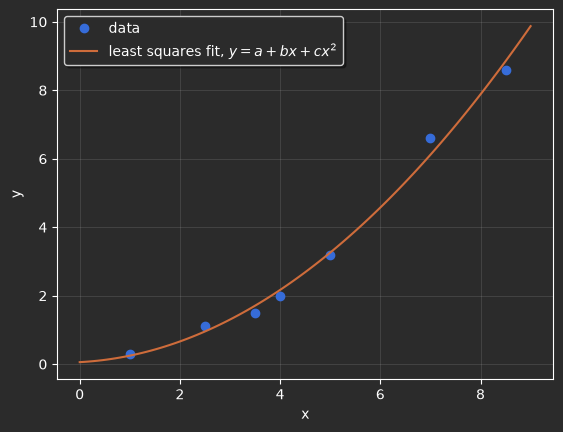

coeficientes --> [0.0578403  0.07701453 0.11262261]
matriz X --> [[7.0000000e+00 3.1500000e+01 1.8175000e+02]
 [3.1500000e+01 1.8175000e+02 1.2056250e+03]
 [1.8175000e+02 1.2056250e+03 8.6921875e+03]]
matriz Y --> [  23.3  151.6 1082.3]


In [28]:
# 4.1)

# Esto lo hice segun como lo recuerdo de analisis numerico I pero si vas a la documentacion de linalg.lstsq(M, M_y) hay un ejemplo donde no tenes que computar la M_y

# Matrices A y b, sumatoria de potencias de las x  a la j= 0...4
# x0 x1 x2
# x1 x2 x3
# x2 x3 x4

# x0.y
# x1.y
# x2.y

x_in = np.array([1.0, 2.5, 3.5, 4.0, 5.0, 7.0, 8.5])
y_in = np.array([0.3, 1.1, 1.5, 2.0, 3.2, 6.6, 8.6])

x0 = sum(map(lambda i: pow(i, 0), x_in))
x1 = sum(map(lambda i: pow(i, 1), x_in))
x2 = sum(map(lambda i: pow(i, 2), x_in))
x3 = sum(map(lambda i: pow(i, 3), x_in))
x4 = sum(map(lambda i: pow(i, 4), x_in))

x0y = sum(map(lambda i, j: pow(i, 0) * j, x_in, y_in))
x1y = sum(map(lambda i, j: pow(i, 1) * j, x_in, y_in))
x2y = sum(map(lambda i, j: pow(i, 2) * j, x_in, y_in))

M = np.array([[x0, x1, x2], [x1, x2, x3], [x2, x3, x4]])
M_y = np.array([x0y, x1y, x2y])

p, res, rnk, s = linalg.lstsq(M, M_y)

plt.plot(x_in, y_in, 'o', label='data')
xx = np.linspace(0, 9, 101)
yy = p[0] + p[1] * xx + p[2] * xx ** 2
plt.plot(xx, yy, label='least squares fit, $y = a + bx + cx^2$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(framealpha=1, shadow=True)
plt.grid(alpha=0.25)
plt.show()

print(f"coeficientes --> {p}")

print(f"matriz X --> {M}")
print(f"matriz Y --> {M_y}")


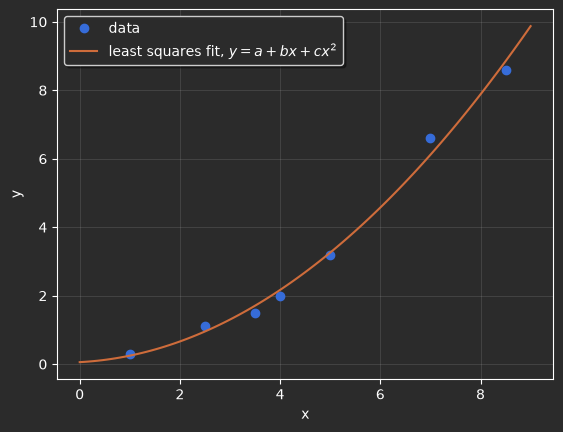

coeficientes --> [[ 1.    1.    1.  ]
 [ 1.    2.5   6.25]
 [ 1.    3.5  12.25]
 [ 1.    4.   16.  ]
 [ 1.    5.   25.  ]
 [ 1.    7.   49.  ]
 [ 1.    8.5  72.25]]
coeficientes --> [0.0578403  0.07701453 0.11262261]


In [25]:
# Voy a hacer lo del tutorial (Le agrego el grafico que no esta ahi para comprobar sin comprar numeritos)

x_in = np.array([1.0, 2.5, 3.5, 4.0, 5.0, 7.0, 8.5])
y_in = np.array([0.3, 1.1, 1.5, 2.0, 3.2, 6.6, 8.6])

X = np.column_stack([x_in ** 0, x_in ** 1, x_in ** 2])
p = linalg.lstsq(X, y_in)[0]

plt.plot(x_in, y_in, 'o', label='data')
xx = np.linspace(0, 9, 101)
yy = p[0] + p[1] * xx + p[2] * xx ** 2
plt.plot(xx, yy, label='least squares fit, $y = a + bx + cx^2$')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(framealpha=1, shadow=True)
plt.grid(alpha=0.25)
plt.show()

print(f"Mi matriz, ver solo las primeras 5 filas --> {X}")
print(f"coeficientes --> {p}")


## **Ejercicio 5)** pseudo-inversa de Moore-Penrose de una matriz

La pseudo-inversa de Moore-Penrose es una generalización de la noción de inversa, que resulta útil porque existe para cualquier matriz de dimensiones y entradas arbitrarias sobre los números reales o complejos.

Si una matriz $A$ es invertible (y por ende cuadrada), existe una matriz $B$ tal $AB=BA=\mathbb{I}$. Dicha matríz $B$ es única (para la $A$ dada) y, por ende, se la denota por $A^{-1}$ y se la denomina inversa de $A$.

Si $A$ no es invertible, luego no existe una matriz $B$ para la cual se cumpla la primera condición $AB=BA=\mathbb{I}$. Sin embargo, se puede ver que siempre existe una matriz $B$ para la cual se cumple:

* $ABA = A$,
* $BAB=B$,
* $AB$ es hermitiana, y
* $BA$ es hermitiana.

Dicha matriz $B$ es única (para la $A$ dada) y, por ende, se la denota por $A^+$ y se la denomina matríz pseudo-inversa de Moore-Penrose de $A$.

Referencias:

* https://en.wikipedia.org/wiki/Moore%E2%80%93Penrose_inverse
* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.pinv.html#scipy.linalg.pinv

**1)** Cree una matriz $A$ de dimensiones $n\times m$ con $n=9$ y $m=6$ de números aleatorios generados a partir de la distribución normal de media 0 y varianza 1.

**2)** Use `linalg.pinv()` para computar la psuedo-inversa de Moore-Penrose $A^+$ de $A$.

**3)** Que dimensiones tiene $A^+$?

**4)** Use `np.allclose()` para verifique que $AA^+A\approx A$.

**5)** Verifique que $A^+AA^+\approx A^+$.

In [32]:
# 5.1)
A = np.random.rand(9, 6)
B = linalg.pinv(A)  # B = A+

print(f"A --> {A}")  # 9x6
print(f"B --> {B}")  # 6x9

print(f"ABA = A --> {np.allclose(A @ B @ A, A)}")
print(f"BAB = B --> {np.allclose(B @ A @ B, B)}")




A --> [[0.80430304 0.95944109 0.35294441 0.81154279 0.335997   0.41227262]
 [0.20896066 0.94857668 0.8802955  0.21204043 0.14136873 0.51553523]
 [0.18570724 0.55920876 0.29219249 0.97357844 0.87275866 0.36729075]
 [0.6471243  0.34061945 0.67673966 0.34500699 0.09293928 0.79078233]
 [0.99102647 0.52947407 0.38028653 0.38646932 0.35772278 0.68756635]
 [0.76985575 0.68898884 0.04350404 0.10497173 0.32112999 0.94885698]
 [0.16815739 0.727953   0.50336823 0.8089277  0.37799951 0.07295791]
 [0.66496668 0.63911525 0.94198786 0.37623513 0.47266517 0.62855082]
 [0.40293969 0.70543641 0.18803385 0.51349782 0.87060852 0.34915522]]
B --> [[ 0.58941191 -0.66558941 -0.78847287 -0.30433071  0.91902214 -0.43772659
  -0.1294923   0.53190342  0.25480051]
 [ 0.48351607  0.77475188 -0.46624096 -0.70302637 -0.26998244  0.44677525
   0.2399913  -0.34738554  0.26057103]
 [-0.32955532  0.23555853 -0.17676706  0.21558774  0.11611127 -0.73008653
   0.04730011  0.82745768 -0.00506016]
 [ 0.41541094 -0.39712918  

## **Ejercicio 6)** Producto de Kronecker

Considere las matrices

\begin{equation}
A = \left(
\begin{array}{cc}
A_{11} & \dots & A_{1m} \\
\vdots & \ddots & \vdots \\
A_{nm} & \dots & A_{nm}
\end{array}
\right)
\end{equation}

y

\begin{equation}
B = \left(
\begin{array}{cc}
B_{11} & \dots & B_{1s} \\
\vdots & \ddots & \vdots \\
B_{r1} & \dots & B_{rs}
\end{array}
\right)
\end{equation}

El producto de Kronecker es la matriz de dimensiones $nr\times ms$ dada por

\begin{equation}
A\otimes B
=
\left(
\begin{array}{cc}
A_{11}B & \dots & A_{1m}B \\
\vdots & \ddots & \vdots \\
A_{n1}B & \dots & A_{nm}B
\end{array}
\right)
=
\left(
\begin{array}{cc}
B_{11}A & \dots & B_{1s}A \\
\vdots & \ddots & \vdots \\
B_{r1}A & \dots & B_{rs}A
\end{array}
\right)
\end{equation}

donde $A_{ij}B$ es un bloque de la matriz $A\otimes B$ igual al producto del escalar $A_{ij}$ por la matriz $B$.
Idem para $B_{ij}A$.

Referencias:

* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.kron.html#scipy.linalg.kron

**1)** Use `linalg.kron()` para calcular el producto de Kronecker de las matrices

\begin{equation}
A = \left(
\begin{array}{cc}
1 & 2 \\
3 & 4 \\
\end{array}
\right)
\end{equation}

y

\begin{equation}
B = \left(
\begin{array}{cc}
1 \\
1 \\
1 \\
\end{array}
\right)
\end{equation}

Que dimensiones tiene $A\otimes B$ en este caso?

**2)** Repita para las matrices

\begin{equation}
A = \left(
\begin{array}{cc}
1 & 2 \\
3 & 4 \\
\end{array}
\right)
\end{equation}

y

\begin{equation}
B = \left(
\begin{array}{cc}
1 & 1 & 1
\end{array}
\right)
\end{equation}

Que dimensiones tiene $A\otimes B$ en este otro caso?

In [33]:
# 6.1)
A = np.array([[1, 2], [3, 4]])
B = np.array([[1], [1], [1]])
B_2 = np.array([[1, 1, 1]])

print(f"A kron B --> {np.kron(A, B)}")
print(f"A kron B_2 --> {np.kron(A, B_2)}")

A kron B --> [[1 2]
 [1 2]
 [1 2]
 [3 4]
 [3 4]
 [3 4]]
A kron B_2 --> [[1 1 1 2 2 2]
 [3 3 3 4 4 4]]


## **Ejercicio 7)** Autovalores y autovectores

Considere una matriz $A$ de $n\times m$. Luego, existen un conjunto de escalares $\{\lambda_1,...,\lambda_n\}$ y un correspondiente conjunto de vectores distintos $\{v_1,...,v_n\}$ tales que

\begin{eqnarray}
Av_i = \lambda_i v_i \;\;\;\; (1)
\end{eqnarray}

para todo $i\in\{1,...,n\}$. Estos $\lambda_i$ y $v_i$ se denominan autovalores y autovectores a derecha de $A$, respectivamente. Los autovalores pueden repetirse, pueden ser nulos y se los suele ordenar de mayor a menor en orden descendiente de sus valores absolutos: $|\lambda_1|\geq |\lambda_2|\geq ...\geq |\lambda_n|\geq 0$. Los autovectores pueden normalizarse, ya que si $v_i$ es autovector, luego $v_i/|v_i|$ también lo es.

Los autovectores constituyen una base del dominio de $A$. Esto es muy útil porque permite escribir cualquier vector $v$ en el dominio de $A$ como una combinación linal de sus autovectores

\begin{eqnarray}
v = \sum_i c_i v_i
\end{eqnarray}

Luego, calcular el producto de $A$ con $v$ resulta muy simple

\begin{eqnarray}
Av = A\left(\sum_i c_i v_i\right) = \sum_i c_iAv_i = \sum_i c_i\lambda_iv_i
\end{eqnarray}

Análogamente, existen un conjunto de escalares $\{\mu_1,...,\mu_m\}$ y un correspondiente conjunto de vectores diferentes $\{u_1,...,u_m\}$ de $A$, llamados autovalores y autovectores a izquierda de $A$, respectivamente, y son tales que

\begin{eqnarray}
u_jA = \mu_j u_j \;\;\;\; (2)
\end{eqnarray}

para todo $j\in\{1,...,m\}$.

**1)** Use `linalg.eigvals()` para calcular los autovalores a derecha de la matriz

\begin{equation}
A = \left(
\begin{array}{cc}
0 & -1 \\
1 &  0
\end{array}
\right)
\end{equation}

Referencias:

* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.eig.html#scipy.linalg.eig

**2)** Use `linalg.eig()` para calcular los autovalores y los correspondientes autovectores a derecha de $A$.

**3)** Verifique que la ecuación $(1)$ se cumple.

**4)** Use `linalg.eig()` para calcular los autovalores y los correspondientes autovectores a izquierda de $A$.

**5)** Verifique que la ecuación $(2)$ se cumple.

In [55]:
# 7.1)
## RIGHT
A = np.array([[0, -1], [1, 0]])

calc = linalg.eig(A)  # default left = False, right = True
print(f"RIGHT: aW,aV,aV normed --> {calc}")
aW = calc[0]
aV = calc[1]

# El primer parametro es una mult. de matrices => @, el segundo es un escalar por una matriz => *
print(f"A @ aV = aW * aV ==> {np.allclose(A @ aV, aW * aV)}")

## LEFT
calc = linalg.eig(A, left=True, right=False)
print(f"LEFT: aW,aV,aV normed --> {calc}")
aW = calc[0]
aV = calc[1]

print(f"aV @ A = aW * aV ==> {np.allclose(aV.conj().T @ A, aW[:, np.newaxis] * aV.conj().T)}")
# In linear algebra, when dealing with complex numbers, a regular transpose (.T) is not enough
# You must use the conjugate transpose also called Hermitian transpose
# np.newaxis == None  change a 1D array of shape (2,) into a 2D column vector of shape (2, 1).

RIGHT: aW,aV,aV normed --> (array([0.+1.j, 0.-1.j]), array([[0.70710678+0.j        , 0.70710678-0.j        ],
       [0.        -0.70710678j, 0.        +0.70710678j]]))
A @ aV = aW * aV ==> True
LEFT: aW,aV,aV normed --> (array([0.+1.j, 0.-1.j]), array([[-0.70710678+0.j        , -0.70710678-0.j        ],
       [ 0.        +0.70710678j,  0.        -0.70710678j]]))
aV @ A = aW * aV ==> True


## **Ejercicio 8)** Singular Value Decomposition (SVD)

Una matriz compleja $A$ de dimensiones $n\times m$ se la puede pensar como una transformación lineal $A:V\to W$ desde un espacio vectorial $V$ de dimensión $m$ a un espacio vectorial $W$ de dimensión $n$.
A $V$ se lo suele llamar espacio de salida y a $W$ espacio de llegada.

Cualquiera sea $A$, siempre existen matrices $L$, $D$ y $R$, de dimensiones $n\times n$, $n\times m$ y $m\times m$, respectivamente, tales que $L$ y $R$ son unitarias, $D$ es diagonal y

\begin{eqnarray}
A = LDR^{\dagger} \;\;\;\; (1)
\end{eqnarray}

Los valores diagonales

\begin{eqnarray}
\sigma_i := D_{ii}
\end{eqnarray}

están definidos para todo $i\in \{1,...,k\}$, donde $k=\min(n,m)$,
se los denomina valores singulares de $A$, son todos reales y no-negativos.
La descomposición siempre puede realizarse de manera tal que $\sigma_1\geq \sigma_2 \geq ... \geq \sigma_k\geq 0$.
El número de valores singulares no nulos es el rango de $A$.

Los vectores columna $l_1,...,l_n$ de $L$ forman una base ortonormal del espacio vectorial de llegada $W$.
Los vectores columna $r_1,...,r_m$ de $R$ forman una base ortonormal del espacio vectorial de salida $V$.
Usando estas propiedades, la ecuación $(1)$ puede reescribirse como

\begin{eqnarray}
A = \sum_{i=1}^k \sigma_i \, (l_i \otimes r_i^{\dagger}) \;\;\;\; (2)
\end{eqnarray}

donde $l_i \otimes r_i^{\dagger}$ es la matriz de dimensiones $n\times m$ resultante del [producto exterior](https://en.wikipedia.org/wiki/Outer_product#Connection_with_the_Kronecker_product) entre la matriz $l_i$ de dimensiones $n\times 1$ y la matriz $r_i^{\dagger}$ de dimensiones $1\times m$.
En otras palabras, la $jk$-esima entrada de la matriz $l_i \otimes r_i^{\dagger}$ es

\begin{eqnarray}
(l_i \otimes r_i^{\dagger})_{jk}
=
(l_i)_{j1}
(r_i^{\dagger})_{1k}
\end{eqnarray}

para cada $j\in \{1,...,n\}$ y $k \in \{1,...,m\}$, donde

\begin{eqnarray}
(r_i^{\dagger})_{1k}
=
(r_i)_{k1}^*
\end{eqnarray}

i.e. es el complejo conjugado de la $k1$-esima entrada de la traspuesta de la matriz $r_i$.

Referencias:

* https://en.wikipedia.org/wiki/Singular_value_decomposition
* https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.svd.html#scipy.linalg.svd

**1)** Cree una matriz compleja $A$ de dimensiones $n\times m$ con $n=9$ y $m=6$, cuyas entradas $a_{ij} = x_{ij} + i y_{ij}$ se computen generando números aleatorios $x_{ij}$ e $y_{ij}$ a partir de una distribución normal de media 0 y varianza 1.

**2)** Use `linalg.svd()` para calcular la SVD de $A$. Dicha función retorna 3 arrays, digamos `L`, `s` y `Rc`, donde `L` denota a la matriz $L$, `s` denota al vector de valores singulares $(\sigma_1,\sigma_2,...,\sigma_k)$ y `Rc` denota a la matriz compleja conjugada $R^{\dagger}$.
Inspeccione las dimensiones de los arrays retornados.

**3)** Use el vector `s` para crear la matriz diagonal $D$ de dimensiones $n\times m$.

**4)** Use `np.allclose()` para verificar numéricamente la ecuación $(1)$.

**5)** Use `np.allclose()` para verificar numéricamente que $L$ y $R$ son matrices unitarias.

In [59]:
# 8.1)
n, m = 9, 6
real = np.random.randn(n, m)
img = np.random.randn(n, m)

A = real + 1j * img

L, s, Rc = linalg.svd(A)

print(f"L shape --> {L.shape}")
print(f"s shape --> {s.shape}")
print(f"Rc shape --> {Rc.shape}")

# Factorizes the matrix `a` into two unitary matrices ``U`` and ``Vh``, and
# a 1-D array ``s`` of singular values (real, non-negative) such that
# ``a == U @ S @ Vh``, where ``S`` is a suitably shaped matrix of zeros with
# main diagonal ``s``.

S = np.zeros((n, m))
for i in range(min(n, m)):
    S[i, i] = s[i]

A1 = L @ S @ Rc
np.allclose(A, A1)



L shape --> (9, 9)
s shape --> (6,)
Rc shape --> (6, 6)


True